# Factors associated with rents

**Goal:** Estimate which apartment characteristics and municipal indicators are associated with the rent, and how strongly (research questions 1–3).

**Data:**
- `data/data_processed/flatfox_rentals_clean.csv` – cleaned rental apartments with net rent and municipal indicators (created in `data_cleaning_rentals.ipynb` from `flatfox_rentals_zentralschweiz.csv`)
- `data/data_processed/gemeinde_indikatoren_zentralschweiz.csv` – all 157 municipalities in Central Switzerland (created in `data_engineering_municipality.ipynb`), used to compare the indicators with each other

**Order:** run `data_cleaning_rentals.ipynb` first.

**Important:** These are associations (correlations), not causal effects. Whenever "influence" or "effect" is mentioned below, a statistical association is meant.

**Structure:**
1. Hypotheses: which relationship do we expect and why?
2. Load data
3. Apartment characteristics and rent
4. Municipal indicators and rent – individually (RQ1)
5. Municipal indicators controlling for apartment characteristics (RQ2)
6. Urban vs. rural comparison (RQ3)
7. Summary

## 1. Hypotheses

Before the analysis we state the direction we expect. This avoids explaining results after the fact.

**Target variable:** net rent per m² and month (CHF/m²). We use the price per m² instead of the total price, because the total price mainly depends on the size of the apartment and would otherwise mask differences between municipalities.

| Variable | Expectation | Reason |
|---|---|---|
| Living area (m²) | – (per m²) | large apartments are cheaper per m² (fixed costs such as kitchen and bathroom are spread over more area) |
| Number of rooms | – (per m²) | like living area; strongly correlated with it |
| Year built | + | new buildings have a higher standard and are let at market prices for the first time |
| Lift, balcony/garden | + | amenities that tenants pay more for |
| Median income | + | higher willingness to pay, attractive residential areas |
| Population density | + | urban location, scarce land, proximity to jobs |
| Employment per 100 residents | + | employment centres attract demand |
| Population growth | + | rising demand |
| Net migration | + | in-migration = demand |
| Foreign residents | + | in Central Switzerland mainly highly qualified immigration to the centres (Zug, Lucerne) |
| Vacancy rate | – | more supply than demand → lower prices |
| Social assistance rate | – | indicator of lower purchasing power |
| Residents aged 65+ | – | rather rural, ageing municipalities |
| Household size | – | larger households are more common in rural family municipalities |
| Single-family buildings | – | rural character, small rental market |
| New dwellings per 1,000 residents | unclear | more construction = more (expensive) new apartments, but also more supply |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "data_processed"

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Load data

We load the cleaned listings (`flatfox_rentals_clean.csv`) and the indicators of all 157 municipalities. We also prepare columns for the analysis: the logarithm of the rent per m² and of the living area (rents are right-skewed; on the log scale, regression effects can be read as percentage changes) and balcony, lift and view as 0/1 variables.

The table shows for each variable the number of available values (`count`), mean, standard deviation, minimum, quartiles (50 % = median) and maximum.

In [2]:
# Municipal indicators: column name -> readable label
INDICATORS = {
    "income_median_chf":                "Median taxable income (CHF, 2022)",
    "population_density_log":           "Population density (log, per km² prod. area)",
    "employment_per_100_residents":     "Employment per 100 residents",
    "population_growth_pct":            "Population growth 2024–25 (%)",
    "net_migration_per_1000_residents": "Net migration per 1,000 residents",
    "foreign_population_pct":           "Foreign residents (%)",
    "vacancy_rate_pct":                 "Vacancy rate (%)",
    "social_assistance_rate_pct":       "Social assistance rate (%)",
    "population_age65plus_pct":         "Residents aged 65+ (%)",
    "household_size_mean":              "Mean household size",
    "single_family_buildings_pct":      "Single-family buildings (%)",
    "new_dwellings_per_1000_residents": "New dwellings per 1,000 residents",
}

df = pd.read_csv(DATA_DIR / "flatfox_rentals_clean.csv")
gemeinden = pd.read_csv(DATA_DIR / "gemeinde_indikatoren_zentralschweiz.csv")

# Density is highly right-skewed (city of Lucerne vs. mountain municipalities) -> log transformation
# (already present in the cleaned dataset, added here for the municipality file)
gemeinden["population_density_log"] = np.log(gemeinden["population_density_productive"])

# Target variable on the log scale (right-skewed distribution, effects readable as % change)
df["log_rent_per_m2"] = np.log(df["rent_net_per_m2"])
df["log_surface"] = np.log(df["surface_living"])

# Amenities as 0/1
df["has_balcony"] = df["attribute_reported_balconygarden"].astype(int)
df["has_lift"] = df["attribute_reported_lift"].astype(int)
df["has_view"] = df["attribute_reported_view"].astype(int)

print(f"Listings: {len(df)}, municipalities with listings: {df['gemeinde_bfs'].nunique()}, municipalities in total: {len(gemeinden)}")
df[["rent_net", "surface_living", "rent_net_per_m2", "number_of_rooms", "floor", "building_age"]].describe().T

Listings: 510, municipalities with listings: 98, municipalities in total: 157


,count,mean,std,min,25%,50%,75%,max
rent_net,510.000,2192.561,979.681,517.000,1572.500,1970.000,2457.500,9000.000
surface_living,510.000,91.143,42.483,23.000,67.000,85.000,106.000,440.000
rent_net_per_m2,510.000,25.211,7.663,11.000,19.677,23.615,29.154,51.818
number_of_rooms,510.000,3.517,1.096,1.000,2.500,3.500,4.500,8.000
floor,480.000,2.567,2.948,-1.000,1.000,2.000,3.000,26.000
building_age,340.000,12.221,17.287,0.000,0.000,6.000,18.000,86.000


## 3. Apartment characteristics and rent

First the characteristics of the apartment itself. They are the control variables for RQ2: if, for example, mainly small apartments are listed in wealthy municipalities, an income effect could in fact be a size effect.

We use the **Spearman rank correlation**, because it does not assume linear relationships or a normal distribution and is robust to outliers.

In [3]:
HOUSING = {
    "surface_living": "Living area (m²)",
    "number_of_rooms": "Number of rooms",
    "floor": "Floor",
    "building_age": "Years since construction/renovation",
    "has_balcony": "Balcony/garden reported",
    "has_lift": "Lift reported",
    "has_view": "View reported",
}

rows = []
for col, label in HOUSING.items():
    sub = df[[col, "rent_net_per_m2", "rent_net"]].dropna()
    rho_m2, p_m2 = stats.spearmanr(sub[col], sub["rent_net_per_m2"])
    rho_tot, p_tot = stats.spearmanr(sub[col], sub["rent_net"])
    rows.append({"Characteristic": label, "n": len(sub),
                 "rho (rent/m²)": rho_m2, "p (rent/m²)": p_m2,
                 "rho (total net rent)": rho_tot, "p (total net rent)": p_tot})

housing_corr = pd.DataFrame(rows).sort_values("rho (rent/m²)", key=abs, ascending=False)
housing_corr

,Characteristic,n,rho (rent/m²),p (rent/m²),rho (total net rent),p (total net rent)
0,Living area (m²),510,-0.411,0.000,0.654,0.000
1,Number of rooms,510,-0.333,0.000,0.584,0.000
3,Years since construction/renovation,340,-0.231,0.000,-0.369,0.000
2,Floor,480,0.197,0.000,0.053,0.248
5,Lift reported,510,0.180,0.000,0.160,0.000
4,Balcony/garden reported,510,-0.063,0.152,0.064,0.149
6,View reported,510,-0.027,0.539,0.023,0.602


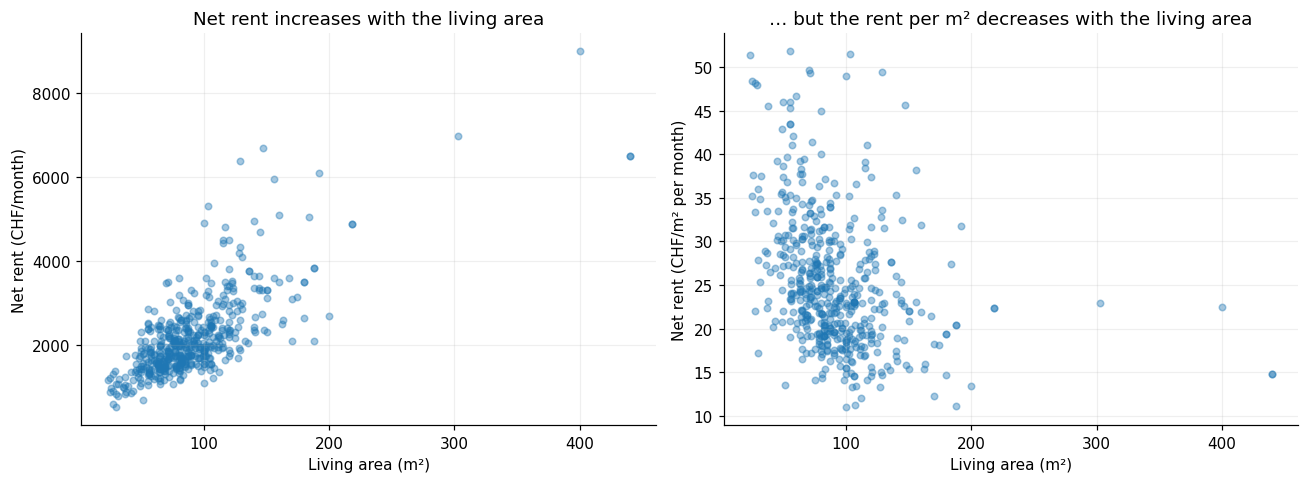

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(df["surface_living"], df["rent_net"], alpha=0.4, s=18)
axes[0].set(title="Net rent increases with the living area", xlabel="Living area (m²)", ylabel="Net rent (CHF/month)")

axes[1].scatter(df["surface_living"], df["rent_net_per_m2"], alpha=0.4, s=18)
axes[1].set(title="… but the rent per m² decreases with the living area", xlabel="Living area (m²)", ylabel="Net rent (CHF/m² per month)")

for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Interpretation:** The living area explains the total rent very strongly (rho = +0.65) but is negatively associated with the price per m² (rho = −0.41, size discount). Living area and number of rooms are strongly correlated and largely measure the same thing. Newer or recently renovated apartments and higher floors are more expensive per m². The year of construction or renovation is only available for two thirds of the listings (340 of 510); it is therefore not used as a control variable, because a third of the sample would otherwise be lost. Balcony/garden is, surprisingly, slightly negatively associated with the rent per m² (not significant), probably because apartments with a balcony are larger on average.

## 4. Municipal indicators individually (research question 1)

**Important methodological point:** The municipal indicators have only one value per municipality. All listings in Lucerne have the same income. If we simply correlated across all listings, the city of Lucerne (about a quarter of all listings) would dominate the result and the p-values would be too optimistic.

We therefore calculate the correlation at **municipality level**: the median rent per m² per municipality, then the Spearman correlation with the indicator. Municipalities with very few listings have an uncertain median; we therefore show both variants (all municipalities / at least 3 listings).

In [5]:
muni = (
    df.groupby("gemeinde_bfs")
    .agg(rent_per_m2_median=("rent_net_per_m2", "median"),
         n_listings=("pk", "size"),
         surface_median=("surface_living", "median"))
    .reset_index()
    .merge(gemeinden, on="gemeinde_bfs", how="left", validate="one_to_one")
)
print(f"Municipalities with listings: {len(muni)}, of which with at least 3 listings: {(muni['n_listings'] >= 3).sum()}")


def spearman_ci(x, y, alpha=0.05):
    # Spearman rho with confidence interval via Fisher z-transformation
    rho, p = stats.spearmanr(x, y)
    n = len(x)
    se = 1.06 / np.sqrt(n - 3)  # correction for Spearman (Fieller et al. 1957)
    z = np.arctanh(rho)
    zc = stats.norm.ppf(1 - alpha / 2)
    return rho, p, np.tanh(z - zc * se), np.tanh(z + zc * se), n


rows = []
for col, label in INDICATORS.items():
    for name, data in [("all municipalities", muni), ("≥3 listings", muni[muni["n_listings"] >= 3])]:
        sub = data[[col, "rent_per_m2_median"]].dropna()
        rho, p, lo, hi, n = spearman_ci(sub[col], sub["rent_per_m2_median"])
        rows.append({"Indicator": label, "column": col, "sample": name,
                     "rho": rho, "CI 2.5%": lo, "CI 97.5%": hi, "p": p, "n municipalities": n})

muni_corr = pd.DataFrame(rows)
table_rq1 = (muni_corr[muni_corr["sample"] == "all municipalities"]
             .sort_values("rho", key=abs, ascending=False)
             .drop(columns=["column", "sample"]))
table_rq1

Municipalities with listings: 98, of which with at least 3 listings: 51


,Indicator,rho,CI 2.5%,CI 97.5%,p,n municipalities
0,"Median taxable income (CHF, 2022)",0.543,0.376,0.676,0.000,98
2,"Population density (log, per km² prod. area)",0.354,0.156,0.525,0.000,98
18,Mean household size,-0.308,-0.487,-0.105,0.002,98
10,Foreign residents (%),0.297,0.093,0.478,0.003,98
16,Residents aged 65+ (%),0.237,0.029,0.426,0.019,98
14,Social assistance rate (%),-0.143,-0.347,0.074,0.170,94
4,Employment per 100 residents,0.123,-0.089,0.324,0.228,98
12,Vacancy rate (%),-0.111,-0.313,0.102,0.278,98
22,"New dwellings per 1,000 residents",0.061,-0.151,0.268,0.550,98
6,Population growth 2024–25 (%),-0.057,-0.264,0.154,0.575,98


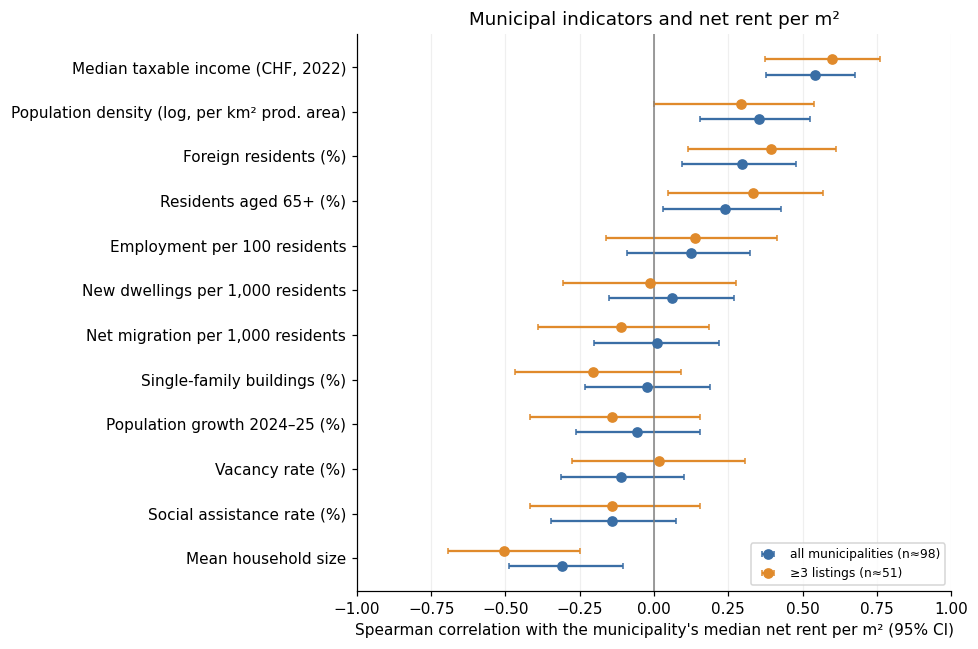

In [6]:
plot = muni_corr.copy()
order = (plot[plot["sample"] == "all municipalities"]
         .sort_values("rho")["Indicator"].tolist())

fig, ax = plt.subplots(figsize=(9, 6))
offsets = {"all municipalities": -0.17, "≥3 listings": 0.17}
colors = {"all municipalities": "#3a6ea5", "≥3 listings": "#e08a2b"}

for name, g in plot.groupby("sample"):
    g = g.set_index("Indicator").loc[order]
    y = np.arange(len(order)) + offsets[name]
    n = int(g["n municipalities"].max())
    ax.errorbar(g["rho"], y, xerr=[g["rho"] - g["CI 2.5%"], g["CI 97.5%"] - g["rho"]],
                fmt="o", color=colors[name], capsize=2, label=f"{name} (n≈{n})")

ax.axvline(0, color="grey", lw=1)
ax.set_yticks(np.arange(len(order)), order)
ax.set(xlabel="Spearman correlation with the municipality's median net rent per m² (95% CI)",
       title="Municipal indicators and net rent per m²", xlim=(-1, 1))
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

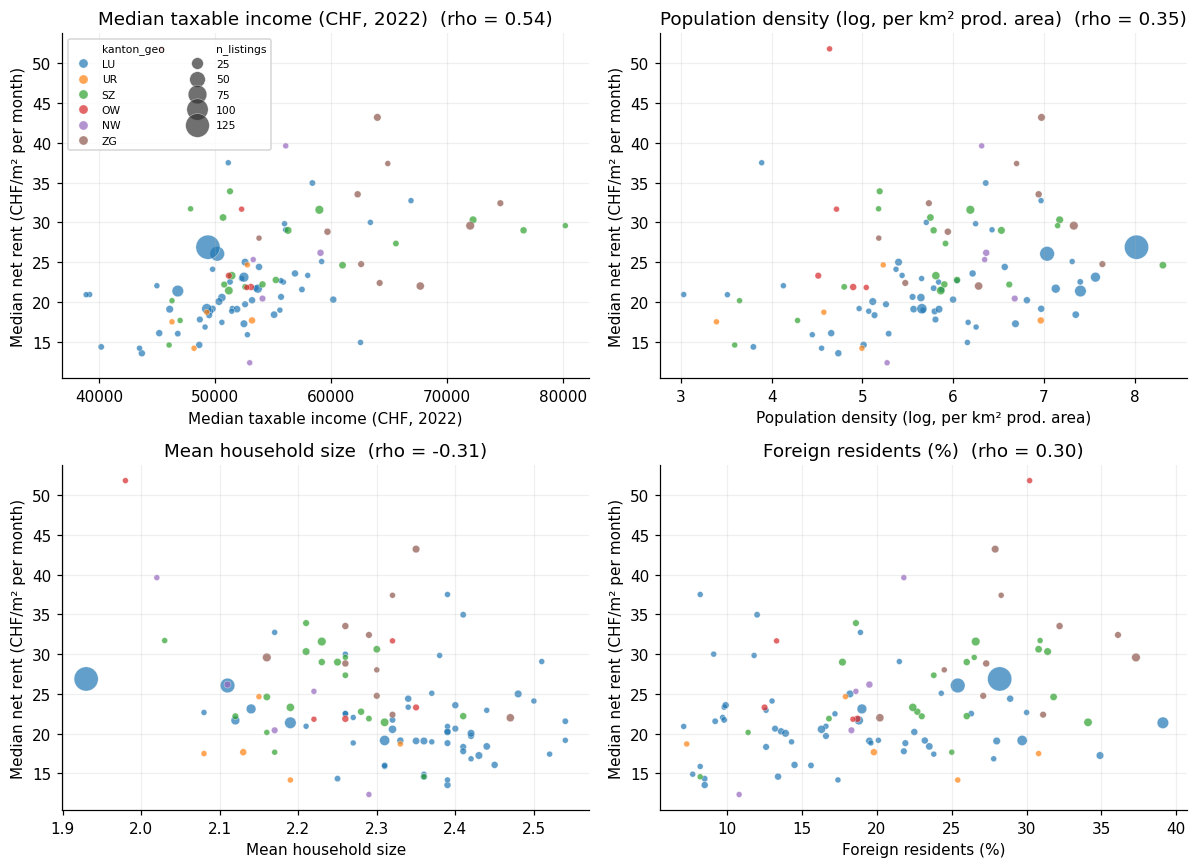

In [7]:
# The four strongest indicators as scatter plots (point size = number of listings)
top4 = table_rq1.head(4)["Indicator"].tolist()
label_to_col = {v: k for k, v in INDICATORS.items()}

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, label in zip(axes.ravel(), top4):
    col = label_to_col[label]
    sns.scatterplot(data=muni, x=col, y="rent_per_m2_median", hue="kanton_geo",
                    size="n_listings", sizes=(15, 250), alpha=0.7, ax=ax, legend=(ax is axes[0, 0]))
    rho = table_rq1.set_index("Indicator").loc[label, "rho"]
    ax.set(title=f"{label}  (rho = {rho:.2f})", xlabel=label, ylabel="Median net rent (CHF/m² per month)")
    ax.grid(alpha=0.2)

axes[0, 0].legend(fontsize=7, loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

### Relationships between the indicators

Many indicators measure similar things (urban vs. rural). The following matrix shows which indicators are strongly correlated with each other. This matters for RQ2: strongly correlated variables can hardly be separated in a joint regression.

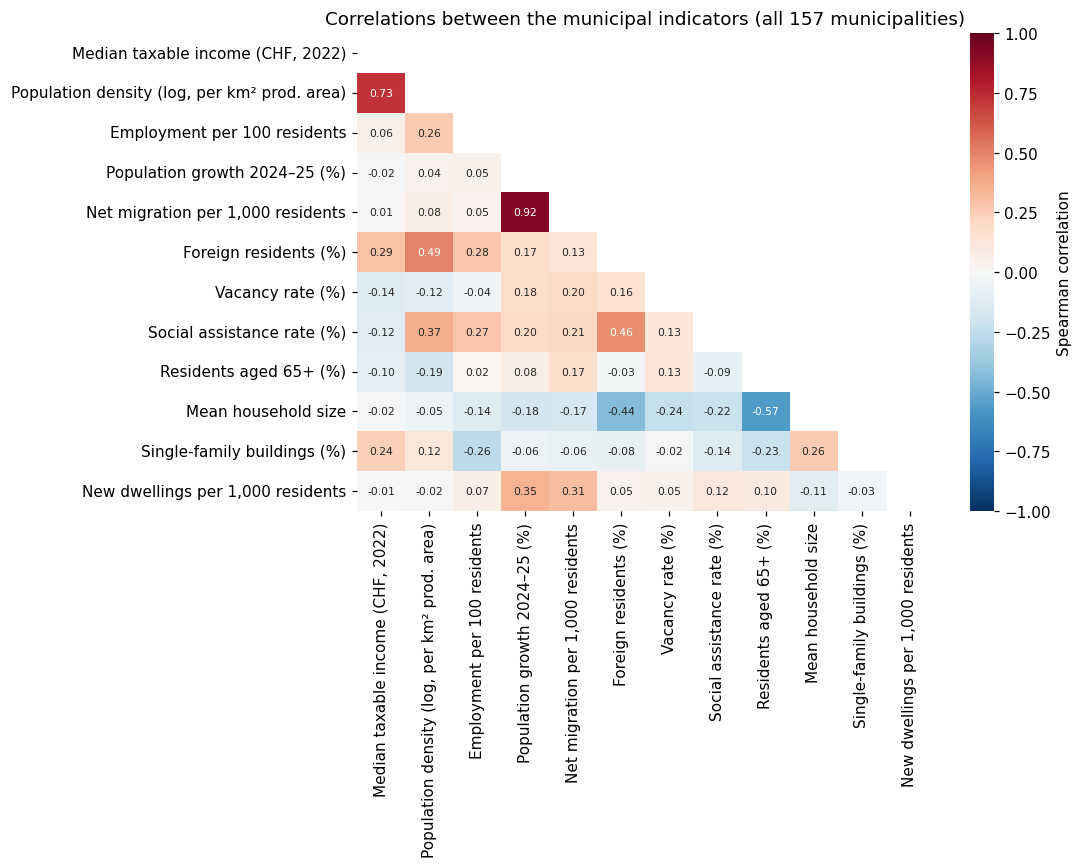

In [8]:
corr_matrix = gemeinden[list(INDICATORS)].rename(columns=INDICATORS).corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            annot_kws={"size": 7}, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Correlations between the municipal indicators (all 157 municipalities)")
plt.tight_layout()
plt.show()

## 5. Indicators controlling for apartment characteristics (research question 2)

Now at listing level, with a linear regression:

$$\log(\text{net rent per m}^2) = \beta_0 + \beta_1 \log(\text{area}) + \beta_2 \,\text{rooms} + \beta_3\,\text{balcony} + \beta_4\,\text{lift} + \gamma \cdot z(\text{indicator}) + \varepsilon$$

- **Log rent:** The coefficient γ can be read as an approximate percentage change: the rent per m² rises by about 100·γ % per standard deviation of the indicator.
- **Standardised indicators (z-scores):** This makes the coefficients comparable across indicators.
- **Cluster-robust standard errors by municipality:** Listings in the same municipality share the indicator value and are not independent. Without this correction the confidence intervals would be far too narrow.

Because the indicators are strongly correlated with each other, we first estimate each indicator separately (always with the apartment controls). Then we test a joint model.

In [9]:
CONTROLS = "log_surface + number_of_rooms + has_balcony + has_lift"

reg = df.copy()
for col in INDICATORS:
    reg[f"z_{col}"] = (reg[col] - reg[col].mean()) / reg[col].std()


def fit_clustered(formula, data):
    data = data.dropna(subset=[c for c in data.columns if c in formula])
    return smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["gemeinde_bfs"]}), data


base_model, base_data = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS}", reg)
print(f"Apartment characteristics only: R² = {base_model.rsquared:.3f}, n = {int(base_model.nobs)}")
base_model.summary().tables[1]

Apartment characteristics only: R² = 0.218, n = 510


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,4.5945,0.252,18.234,0.000,4.101,5.088
log_surface,-0.3404,0.067,-5.076,0.000,-0.472,-0.209
number_of_rooms,0.0183,0.021,0.858,0.391,-0.023,0.060
has_balcony,-0.0441,0.025,-1.799,0.072,-0.092,0.004
has_lift,0.1266,0.027,4.726,0.000,0.074,0.179


In [10]:
rows = []
for col, label in INDICATORS.items():
    model, data = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS} + z_{col}", reg)
    # R² of the base model on the same observations (because of missing values)
    base_same, _ = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS}", data)
    lo, hi = model.conf_int().loc[f"z_{col}"]
    rows.append({
        "Indicator": label,
        "Effect per SD (%)": 100 * (np.exp(model.params[f"z_{col}"]) - 1),
        "CI 2.5% (%)": 100 * (np.exp(lo) - 1),
        "CI 97.5% (%)": 100 * (np.exp(hi) - 1),
        "p (cluster)": model.pvalues[f"z_{col}"],
        "R² gain": model.rsquared - base_same.rsquared,
        "n": int(model.nobs),
    })

table_rq2 = pd.DataFrame(rows).sort_values("R² gain", ascending=False).reset_index(drop=True)
table_rq2

,Indicator,Effect per SD (%),CI 2.5% (%),CI 97.5% (%),p (cluster),R² gain,n
0,"Median taxable income (CHF, 2022)",11.294,6.987,15.775,0.000,0.132,510
1,"Population density (log, per km² prod. area)",7.490,4.396,10.677,0.000,0.060,510
2,Mean household size,-6.524,-9.640,-3.300,0.000,0.051,510
3,Foreign residents (%),5.730,-0.298,12.123,0.063,0.036,510
4,Employment per 100 residents,5.617,1.939,9.428,0.003,0.035,510
5,Residents aged 65+ (%),5.177,1.674,8.800,0.003,0.030,510
6,Vacancy rate (%),-4.213,-7.024,-1.316,0.005,0.022,510
7,Single-family buildings (%),-4.181,-6.810,-1.478,0.003,0.021,510
8,Population growth 2024–25 (%),-2.461,-6.316,1.552,0.226,0.007,510
9,Social assistance rate (%),2.054,-2.126,6.412,0.341,0.005,505


In [11]:
# Comparison: ranking RQ1 (individually) vs. RQ2 (with controls)
ranking = (
    table_rq1[["Indicator", "rho"]]
    .assign(**{"Rank RQ1": lambda t: t["rho"].abs().rank(ascending=False).astype(int)})
    .merge(table_rq2[["Indicator", "Effect per SD (%)", "R² gain"]], on="Indicator")
    .assign(**{"Rank RQ2": lambda t: t["R² gain"].rank(ascending=False).astype(int)})
    .sort_values("Rank RQ2")
)
ranking

,Indicator,rho,Rank RQ1,Effect per SD (%),R² gain,Rank RQ2
0,"Median taxable income (CHF, 2022)",0.543,1,11.294,0.132,1
1,"Population density (log, per km² prod. area)",0.354,2,7.490,0.060,2
2,Mean household size,-0.308,3,-6.524,0.051,3
3,Foreign residents (%),0.297,4,5.730,0.036,4
6,Employment per 100 residents,0.123,7,5.617,0.035,5
4,Residents aged 65+ (%),0.237,5,5.177,0.030,6
7,Vacancy rate (%),-0.111,8,-4.213,0.022,7
10,Single-family buildings (%),-0.023,11,-4.181,0.021,8
9,Population growth 2024–25 (%),-0.057,10,-2.461,0.007,9
5,Social assistance rate (%),-0.143,6,2.054,0.005,10


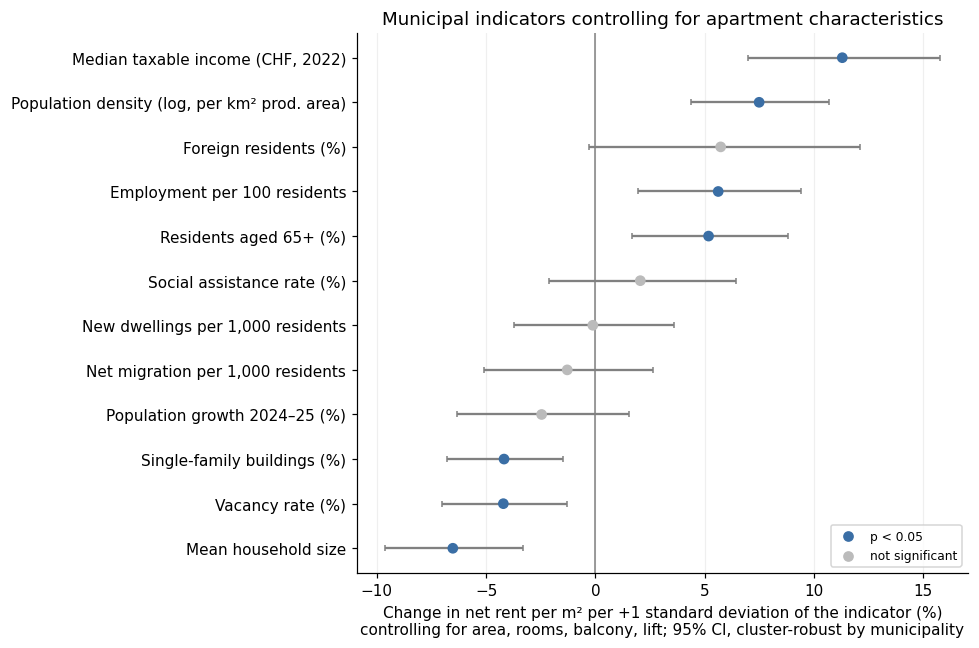

In [12]:
plot = table_rq2.sort_values("Effect per SD (%)")
fig, ax = plt.subplots(figsize=(9, 6))
significant = plot["p (cluster)"] < 0.05
ax.errorbar(plot["Effect per SD (%)"], plot["Indicator"],
            xerr=[plot["Effect per SD (%)"] - plot["CI 2.5% (%)"], plot["CI 97.5% (%)"] - plot["Effect per SD (%)"]],
            fmt="none", ecolor="grey", capsize=2)
ax.scatter(plot["Effect per SD (%)"], plot["Indicator"], c=np.where(significant, "#3a6ea5", "#bbbbbb"), zorder=3)
ax.axvline(0, color="grey", lw=1)
ax.set(xlabel="Change in net rent per m² per +1 standard deviation of the indicator (%)\n"
              "controlling for area, rooms, balcony, lift; 95% CI, cluster-robust by municipality",
       title="Municipal indicators controlling for apartment characteristics")
ax.grid(axis="x", alpha=0.2)
ax.scatter([], [], c="#3a6ea5", label="p < 0.05")
ax.scatter([], [], c="#bbbbbb", label="not significant")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### Joint model

Including all indicators in one model is problematic if they are strongly correlated (multicollinearity). We check this with the variance inflation factor (VIF): values above about 5 mean that an indicator is largely explained by the others and its coefficient is unreliable.

In [13]:
full_cols = list(INDICATORS)
X = reg[[f"z_{c}" for c in full_cols]].dropna()
vif = pd.DataFrame({
    "Indicator": [INDICATORS[c] for c in full_cols],
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
}).sort_values("VIF", ascending=False)
vif

,Indicator,VIF
3,Population growth 2024–25 (%),20.433
4,"Net migration per 1,000 residents",19.653
7,Social assistance rate (%),9.138
9,Mean household size,8.767
1,"Population density (log, per km² prod. area)",4.990
10,Single-family buildings (%),4.986
0,"Median taxable income (CHF, 2022)",3.006
2,Employment per 100 residents,2.310
5,Foreign residents (%),1.973
8,Residents aged 65+ (%),1.971


In [14]:
# Reduced model: remove indicators with VIF > 5 step by step (always the highest)
selected = list(full_cols)
while True:
    X = reg[[f"z_{c}" for c in selected]].dropna()
    v = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=selected)
    if v.max() <= 5:
        break
    print(f"removed: {INDICATORS[v.idxmax()]} (VIF {v.max():.1f})")
    selected.remove(v.idxmax())

formula = f"log_rent_per_m2 ~ {CONTROLS} + " + " + ".join(f"z_{c}" for c in selected)
joint_model, joint_data = fit_clustered(formula, reg)
print(f"\nJoint model: R² = {joint_model.rsquared:.3f}, adj. R² = {joint_model.rsquared_adj:.3f}, "
      f"n = {int(joint_model.nobs)}, municipalities = {joint_data['gemeinde_bfs'].nunique()}")

joint = pd.DataFrame({
    "Effect per SD (%)": 100 * (np.exp(joint_model.params) - 1),
    "p (cluster)": joint_model.pvalues,
}).loc[[f"z_{c}" for c in selected]]
joint.index = [INDICATORS[c] for c in selected]
joint.sort_values("p (cluster)")

removed: Population growth 2024–25 (%) (VIF 20.4)
removed: Social assistance rate (%) (VIF 9.1)
removed: Mean household size (VIF 7.0)

Joint model: R² = 0.444, adj. R² = 0.429, n = 510, municipalities = 98


,Effect per SD (%),p (cluster)
"Median taxable income (CHF, 2022)",11.304,0.000
Residents aged 65+ (%),3.602,0.026
"Population density (log, per km² prod. area)",3.815,0.065
Single-family buildings (%),-4.037,0.096
Vacancy rate (%),-1.859,0.200
Foreign residents (%),2.838,0.205
"New dwellings per 1,000 residents",0.802,0.553
Employment per 100 residents,-0.861,0.629
"Net migration per 1,000 residents",0.028,0.984


### Robustness check

Two checks of whether the results depend on decisions made during cleaning:

1. **Gross rent instead of net rent:** For some listings the net rent was derived as gross rent − service charges. With the gross rent as target variable, direction and ranking should remain similar.
2. **Only directly reported net rents:** The derived net rents are left out.

If the effects are similar in all variants, the conclusions do not depend on these decisions.

In [15]:
variants = {
    "gross rent": reg.assign(
        log_rent_per_m2=np.log(reg["rent_gross"].fillna(reg["rent_net"] + reg["rent_charges"]) / reg["surface_living"])
    ),
    "reported net rent only": reg[reg["rent_net_source"] == "reported"],
}

robust = table_rq2[["Indicator", "Effect per SD (%)", "p (cluster)"]].copy()
for name, data in variants.items():
    rows = []
    for col, label in INDICATORS.items():
        model, _ = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS} + z_{col}", data)
        rows.append({"Indicator": label,
                     f"Effect (%) {name}": 100 * (np.exp(model.params[f"z_{col}"]) - 1),
                     f"p {name}": model.pvalues[f"z_{col}"],
                     f"n {name}": int(model.nobs)})
    robust = robust.merge(pd.DataFrame(rows), on="Indicator")
    agreement = stats.spearmanr(robust["Effect per SD (%)"], robust[f"Effect (%) {name}"])[0]
    print(f"Rank agreement net rent vs. {name}: {agreement:.2f}")

robust

Rank agreement net rent vs. gross rent: 0.99
Rank agreement net rent vs. reported net rent only: 0.98


,Indicator,Effect per SD (%),p (cluster),Effect (%) gross rent,p gross rent,n gross rent,Effect (%) reported net rent only,p reported net rent only,n reported net rent only
0,"Median taxable income (CHF, 2022)",11.294,0.000,11.058,0.000,501,10.739,0.000,435
1,"Population density (log, per km² prod. area)",7.490,0.000,6.736,0.000,501,7.942,0.000,435
2,Mean household size,-6.524,0.000,-5.825,0.001,501,-7.075,0.000,435
3,Foreign residents (%),5.730,0.063,5.775,0.034,501,5.952,0.058,435
4,Employment per 100 residents,5.617,0.003,4.957,0.004,501,5.926,0.003,435
5,Residents aged 65+ (%),5.177,0.003,5.227,0.001,501,5.743,0.001,435
6,Vacancy rate (%),-4.213,0.005,-3.695,0.004,501,-3.031,0.108,435
7,Single-family buildings (%),-4.181,0.003,-3.458,0.005,501,-4.510,0.006,435
8,Population growth 2024–25 (%),-2.461,0.226,-2.323,0.229,501,-3.125,0.140,435
9,Social assistance rate (%),2.054,0.341,1.407,0.452,496,3.303,0.138,434


## 6. Urban vs. rural comparison (research question 3)

**Question:** Do the relationships from RQ1 and RQ2 apply equally in urban and rural municipalities, or do the strength and ranking of the indicators differ?

**Classification:** the official **urban/rural typology of the FSO** (municipality typology 2020, municipalities as of 1 January 2026; file `data/demographic_data/raumgliederungen_bfs.xlsx`, exported from the FSO's historicised municipality directory). It distinguishes urban, intermediate (dense peri-urban areas and rural centres) and rural. Intermediate and rural municipalities have only 88 and 76 apartments in our sample; for the comparison we therefore combine them into "intermediate/rural" and compare them with the urban municipalities.

**Limitation:** With 164 apartments, the intermediate/rural group is much smaller than the urban group (346 apartments). Its results are correspondingly less certain.

In [16]:
TYPOLOGY_FILE = PROJECT_DIR / "data" / "demographic_data" / "raumgliederungen_bfs.xlsx"

# Sheet "Daten": row 2 contains the column names, row 3 the code list IDs (skipped)
typology = pd.read_excel(TYPOLOGY_FILE, sheet_name="Daten", header=1, skiprows=[2])
typology = typology.rename(columns={"BFS Gde-nummer": "gemeinde_bfs", "Stadt/Land-Typologie": "stadt_land_code"})
typology["stadt_land"] = typology["stadt_land_code"].map({1: "urban", 2: "intermediate", 3: "rural"})
typology["urban_rural"] = typology["stadt_land"].replace({"intermediate": "intermediate/rural", "rural": "intermediate/rural"})

reg = reg.drop(columns=["stadt_land", "urban_rural"], errors="ignore").merge(
    typology[["gemeinde_bfs", "stadt_land", "urban_rural"]], on="gemeinde_bfs", how="left", validate="many_to_one")
assert reg["urban_rural"].notna().all(), "municipality without urban/rural typology"

print("All municipalities in Central Switzerland by typology:")
display(gemeinden.merge(typology[["gemeinde_bfs", "stadt_land"]], on="gemeinde_bfs", how="left")["stadt_land"].value_counts())

GROUPS = ["urban", "intermediate/rural"]
overview = reg.groupby("stadt_land").agg(
    apartments=("pk", "size"),
    municipalities=("gemeinde_bfs", "nunique"),
    median_net_rent_per_m2=("rent_net_per_m2", "median"),
    median_area=("surface_living", "median"),
).reindex(["urban", "intermediate", "rural"])
overview

All municipalities in Central Switzerland by typology:


stadt_land
rural           75
urban           42
intermediate    40
Name: count, dtype: int64

,apartments,municipalities,median_net_rent_per_m2,median_area
stadt_land,,,,
urban,346,38,25.557,80.000
intermediate,88,30,20.774,91.000
rural,76,30,19.357,97.500


In [17]:
RQ3_INDICATORS = INDICATORS

# RQ1 per group: Spearman at municipality level
muni_groups = muni.merge(reg.groupby("gemeinde_bfs")["urban_rural"].first().reset_index(), on="gemeinde_bfs")

rows = []
for group in GROUPS:
    data = muni_groups[muni_groups["urban_rural"] == group]
    for col, label in RQ3_INDICATORS.items():
        sub = data[[col, "rent_per_m2_median"]].dropna()
        rho, p, lo, hi, n = spearman_ci(sub[col], sub["rent_per_m2_median"])
        rows.append({"Indicator": label, "group": group, "rho": rho, "p": p, "n municipalities": n})
rq3_corr = pd.DataFrame(rows).pivot(index="Indicator", columns="group", values=["rho", "p"])
rq3_corr.columns = [f"{a} {b}" for a, b in rq3_corr.columns]
rq3_corr = rq3_corr[["rho urban", "p urban", "rho intermediate/rural", "p intermediate/rural"]].sort_values("rho urban", key=abs, ascending=False)
rq3_corr

,rho urban,p urban,rho intermediate/rural,p intermediate/rural
Indicator,,,,
"Median taxable income (CHF, 2022)",0.408,0.011,0.545,0.000
Foreign residents (%),0.261,0.114,0.101,0.441
Employment per 100 residents,0.200,0.229,-0.157,0.232
Social assistance rate (%),-0.179,0.281,-0.390,0.003
Vacancy rate (%),-0.156,0.350,0.006,0.965
Residents aged 65+ (%),-0.121,0.470,0.292,0.023
Population growth 2024–25 (%),-0.073,0.661,0.021,0.873
"New dwellings per 1,000 residents",0.056,0.739,0.170,0.193
Single-family buildings (%),-0.047,0.777,0.079,0.548


In [18]:
# RQ2 per group: separate models with apartment controls, cluster-robust by municipality
rows = []
for group in GROUPS:
    data = reg[reg["urban_rural"] == group].copy()
    # z-scores within the group, so that "1 SD" refers to the spread within the group
    for col in RQ3_INDICATORS:
        data[f"zg_{col}"] = (data[col] - data[col].mean()) / data[col].std()
    for col, label in RQ3_INDICATORS.items():
        if data[col].nunique() < 3:
            continue
        model, used = fit_clustered(f"log_rent_per_m2 ~ {CONTROLS} + zg_{col}", data)
        lo, hi = model.conf_int().loc[f"zg_{col}"]
        rows.append({"Indicator": label, "group": group,
                     "Effect (%)": 100 * (np.exp(model.params[f"zg_{col}"]) - 1),
                     "CI 2.5% (%)": 100 * (np.exp(lo) - 1), "CI 97.5% (%)": 100 * (np.exp(hi) - 1),
                     "p": model.pvalues[f"zg_{col}"], "n": int(model.nobs),
                     "municipalities": used["gemeinde_bfs"].nunique()})

rq3_reg = pd.DataFrame(rows)
rq3_wide = rq3_reg.pivot(index="Indicator", columns="group", values=["Effect (%)", "p"])
rq3_wide.columns = [f"{a} {b}" for a, b in rq3_wide.columns]
rq3_wide = rq3_wide[["Effect (%) urban", "p urban", "Effect (%) intermediate/rural", "p intermediate/rural"]]

rank_corr_rho = stats.spearmanr(rq3_corr["rho urban"], rq3_corr["rho intermediate/rural"])[0]
rank_corr_reg = stats.spearmanr(rq3_wide["Effect (%) urban"], rq3_wide["Effect (%) intermediate/rural"])[0]
print(f"Rank agreement urban vs. intermediate/rural – correlations (RQ1): {rank_corr_rho:.2f}")
print(f"Rank agreement urban vs. intermediate/rural – regression effects (RQ2): {rank_corr_reg:.2f}")
rq3_wide.sort_values("Effect (%) urban")

Rank agreement urban vs. intermediate/rural – correlations (RQ1): 0.45
Rank agreement urban vs. intermediate/rural – regression effects (RQ2): 0.52


,Effect (%) urban,p urban,Effect (%) intermediate/rural,p intermediate/rural
Indicator,,,,
Vacancy rate (%),-5.179,0.036,-2.511,0.059
Social assistance rate (%),-3.870,0.121,-5.971,0.012
Population growth 2024–25 (%),-2.382,0.196,-3.266,0.145
"Net migration per 1,000 residents",-1.789,0.396,-2.911,0.170
"Population density (log, per km² prod. area)",-1.315,0.423,4.300,0.129
"New dwellings per 1,000 residents",-0.471,0.889,2.700,0.176
Single-family buildings (%),-0.436,0.793,1.829,0.512
Foreign residents (%),-0.025,0.994,2.988,0.442
Mean household size,0.886,0.681,-7.156,0.008


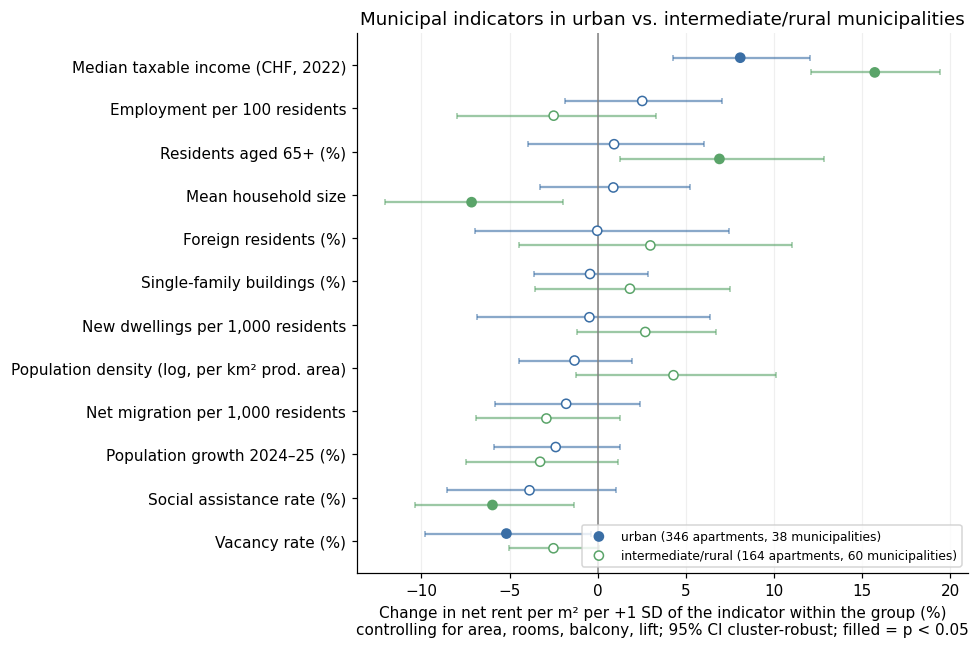

In [19]:
order = rq3_wide.sort_values("Effect (%) urban").index.tolist()
colors = {"urban": "#3a6ea5", "intermediate/rural": "#5aa469"}
offsets = {"urban": 0.17, "intermediate/rural": -0.17}

fig, ax = plt.subplots(figsize=(9, 6))
for group in GROUPS:
    g = rq3_reg[rq3_reg["group"] == group].set_index("Indicator").reindex(order)
    y = np.arange(len(order)) + offsets[group]
    sig = g["p"] < 0.05
    ax.errorbar(g["Effect (%)"], y, xerr=[g["Effect (%)"] - g["CI 2.5% (%)"], g["CI 97.5% (%)"] - g["Effect (%)"]],
                fmt="none", ecolor=colors[group], alpha=0.6, capsize=2)
    ax.scatter(g["Effect (%)"], y, facecolors=np.where(sig, colors[group], "white"), edgecolors=colors[group], zorder=3,
               label=f"{group} ({int(g['n'].max())} apartments, {int(g['municipalities'].max())} municipalities)")
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(np.arange(len(order)), order)
ax.set(xlabel="Change in net rent per m² per +1 SD of the indicator within the group (%)\n"
              "controlling for area, rooms, balcony, lift; 95% CI cluster-robust; filled = p < 0.05",
       title="Municipal indicators in urban vs. intermediate/rural municipalities")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretation RQ3

- **Rent level:** The net rent per m² falls from urban (median CHF 25.6) to intermediate (20.8) and rural municipalities (19.4).

- **Stable:** Median income is the strongest indicator in both groups (urban +8.1 %, intermediate/rural +15.7 % per standard deviation within the group). The social assistance rate (−3.9 % / −6.0 %) and the vacancy rate (−5.2 % / −2.5 %) are negatively associated with the rent in both groups, but each is significant in only one group.

- **Not stable:** Household size (−7.2 %) and the share of residents aged 65+ (+6.9 %) are only significant in intermediate/rural municipalities. Population density is positive there (+4.3 %, not significant) and plays no role at all within the cities (−1.3 %). Employment, foreign residents, growth, migration, new dwellings and single-family buildings are not significant in either group: their association in RQ1/RQ2 mainly reflected the difference between urban and rural municipalities.

- **Social assistance rate:** In the full sample it is not significant (slightly positive in the regression), but negative within both groups. Cities have both higher rents and higher social assistance rates; the expected negative relationship only appears within comparable municipalities.

- **Ranking:** The ranking of the indicators agrees only moderately between the groups (0.45 for the correlations, 0.52 for the regression effects). Mainly the top (income) is stable.

- **Caution:** The intermediate/rural group comprises only 164 apartments in 60 municipalities, and the apartment characteristics explain much less there (R² 0.13 compared with 0.27 in urban municipalities). The results for this group are correspondingly uncertain.

## 7. Summary

The figures in this section are generated automatically from the tables above when the notebook is run.

In [20]:
print("RQ1 – strongest individual associations (municipality level, Spearman):")
for _, r in table_rq1.head(5).iterrows():
    sig = "significant" if r["p"] < 0.05 else "not significant"
    print(f"  {r['Indicator']:<50} rho = {r['rho']:+.2f}  ({sig})")

print("\nRQ2 – controlling for apartment characteristics (sorted by R² gain):")
print(f"  Apartment characteristics alone explain R² = {base_model.rsquared:.2f}")
for _, r in table_rq2.head(5).iterrows():
    sig = "significant" if r["p (cluster)"] < 0.05 else "not significant"
    print(f"  {r['Indicator']:<50} {r['Effect per SD (%)']:+.1f}% per SD, R² gain {r['R² gain']:.3f}  ({sig})")

print(f"\nJoint model (VIF <= 5): R² = {joint_model.rsquared:.2f}")

print("\nRQ3 – urban vs. intermediate/rural (rank agreement):")
print(f"  correlations: {rank_corr_rho:.2f}, regression effects: {rank_corr_reg:.2f}")
for group in GROUPS:
    top = rq3_reg[(rq3_reg["group"] == group)].sort_values("p").head(3)
    items = ", ".join(f"{r['Indicator']} ({r['Effect (%)']:+.1f}%)" for _, r in top.iterrows())
    print(f"  {group}: {items}")

RQ1 – strongest individual associations (municipality level, Spearman):
  Median taxable income (CHF, 2022)                  rho = +0.54  (significant)
  Population density (log, per km² prod. area)       rho = +0.35  (significant)
  Mean household size                                rho = -0.31  (significant)
  Foreign residents (%)                              rho = +0.30  (significant)
  Residents aged 65+ (%)                             rho = +0.24  (significant)

RQ2 – controlling for apartment characteristics (sorted by R² gain):
  Apartment characteristics alone explain R² = 0.22
  Median taxable income (CHF, 2022)                  +11.3% per SD, R² gain 0.132  (significant)
  Population density (log, per km² prod. area)       +7.5% per SD, R² gain 0.060  (significant)
  Mean household size                                -6.5% per SD, R² gain 0.051  (significant)
  Foreign residents (%)                              +5.7% per SD, R² gain 0.036  (not significant)
  Employment per 

### Interpretation (data from 18 October to 6 November 2026, 510 apartments, 98 municipalities, net rent)

**Apartment characteristics:** The living area is the strongest single characteristic: large apartments cost more in total (rho = +0.65) but less per m² (rho = −0.41). Newer or recently renovated apartments, higher floors and apartments with a lift are more expensive per m². Area, rooms, balcony and lift together explain about 22 % of the variation in the net rent per m².

**RQ1 – individually:** The net rent per m² is most strongly associated with the municipality's **median income** (rho = +0.54). It is followed by **population density** (+0.35), **household size** (−0.31), **foreign residents** (+0.30) and **residents aged 65+** (+0.24). Social assistance rate, employment, vacancy rate, new dwellings, growth, single-family buildings and net migration show no significant individual association.

**RQ2 – with controls:** Income remains clearly at the top (+11.3 % net rent per m² per standard deviation), followed by density (+7.5 %), household size (−6.5 %), employment per 100 residents (+5.6 %), residents aged 65+ (+5.2 %), **vacancy rate** (−4.2 %) and **single-family buildings** (−4.2 %). Employment, vacancy rate and single-family buildings only become visible once apartment size is controlled for. Foreign residents, on the other hand, are no longer significant (+5.7 %, p = 0.06). In the joint model (without collinear variables; growth, social assistance rate and household size removed), only **income** (+11.3 %) and **residents aged 65+** (+3.6 %) remain significant; density and single-family buildings point in the same direction as before but are no longer significant. The municipal indicators increase the R² from 0.22 to 0.44.

**Comparison with the hypotheses:**
- Confirmed: income (+), density (+), employment (+, with controls), vacancy rate (−, with controls), household size (−), single-family buildings (−, with controls).
- Partly confirmed: foreign residents (+) are significant individually, but no longer once apartment characteristics are controlled for.
- Not confirmed: population growth, net migration and new dwellings show no association. A possible reason is that a single year of growth (2024–25) is a very short-term, fluctuating measure. The social assistance rate only shows the expected negative association within comparable municipalities (see RQ3).
- Contrary to expectations: **residents aged 65+** is positive. A possible explanation is wealthy lakeside municipalities with an older population (e.g. on Lake Lucerne); this remains to be tested.

**Robustness:** With the gross rent instead of the net rent (rank agreement 0.99) and with only directly reported net rents (0.98), the picture remains practically the same.

**Caution:** Income, density, foreign residents and employment all partly measure the same thing (urban, economically strong location). Which of these factors actually drives prices cannot be separated with observational data.

**Limitations**
- Associations, not causality: income, density and foreign residents are all related to an "urban location". Which factor actually drives prices cannot be separated with these data.
- The effective sample size for the municipal indicators is the number of municipalities (98), not the number of listings. Many municipalities have only 1–3 listings (59 of 98).
- The sample is strongly concentrated in the canton of Lucerne (363 of 510 apartments); Uri (8 listings), Obwalden (10) and Nidwalden (10) are barely represented, because few listings are published there and many do not state a net rent.
- Listings show asking rents, not rents actually paid, and only Flatfox listings collected over about three weeks (18 October to 6 November 2026).
- Unobserved characteristics (condition, micro-location, view) may be related to the indicators.